# 第 10 堂：分類模型（KNN 與決策樹）
LESSON 10 · CLASSIFICATION: KNN & DECISION TREE

### 本堂學習目標
學完後，你應該能夠：
1. 分辨迴歸和分類的差別，知道分類模型的 `score()` 是**正確率**。
2. 說出 KNN 的原理：**找最近的 K 個鄰居，多數決**。
3. 說出決策樹的原理：**用一連串的是非題做判斷**。
4. 用 `KNeighborsClassifier` 和 `DecisionTreeClassifier` 完成分類流程。
5. 把決策樹畫出來，並用白話讀出它的判斷規則。
6. 知道 K 和樹的深度會影響結果，並初步看到「背答案」的現象。

### 本堂上課順序
| 順序 | 內容 |
| :--- | :--- |
| 1. 生活例子 | 健身房怎麼猜會員會不會續約？ |
| 2. 概念解說 | 分類 vs 迴歸、KNN、決策樹 |
| 3. 程式教學 | 資料 → 畫圖 → KNN → 決策樹 → 比較 |
| 4. 逐行解析 | 每段程式後面都有解析表 |
| 5. 實際練習 | 4 個練習，附參考解答 |
| 6. 小考驗收 | 自我檢查，再回對話做小考 |

---
## 一、生活例子：健身房怎麼猜會員會不會續約？

你是健身房的店長，下個月有一批會員合約到期。你想提早知道**誰可能不續約**，好讓教練先去關心他們。

你手上有過去 60 位會員的紀錄：
- **每月到店次數**（特徵）
- **會員年資**（特徵）
- **最後有沒有續約**（標籤：續約／流失）

### 店長 A 的方法：看看跟他很像的人
> 「小美每月來 8 次、當會員 4 年。我想想以前跟她差不多的會員……最像的 5 個人裡有 4 個續約了，那小美應該也會續約。」

這就是 **KNN（K 個最近的鄰居）**。

### 店長 B 的方法：問幾個是非題
> 「先問：年資超過 3 年嗎？
> 　→ 是：再問每月來超過 4 次嗎？是 → 續約；否 → 流失
> 　→ 否：再問每月來超過 11 次嗎？是 → 續約；否 → 流失」

這就是**決策樹**。

兩個店長都是從過去的資料學會判斷方法，這兩種方法就是今天要學的兩個分類模型。

---
## 二、概念解說

### 1. 分類 vs 迴歸（第 2 堂複習）

| 比較 | 迴歸（第 9 堂） | 分類（今天） |
| :--- | :--- | :--- |
| 預測什麼 | **數字** | **類別** |
| 例子 | 房價 830 萬、車資 335 元 | 續約／流失、垃圾信／正常信 |
| 模型 | `LinearRegression` | `KNeighborsClassifier`、`DecisionTreeClassifier` |
| `score()` 是什麼 | R²（越接近 1 越好） | **正確率** Accuracy（答對幾成） |

兩者都屬於**監督式學習**，因為訓練資料裡都有正確答案（標籤）。
**流程完全一樣**（第 8 堂九步驟），只是換一個模型。

注意：分類模型名字後面都有 **Classifier**（分類器），迴歸模型通常有 **Regression** 或 **Regressor**。

### 2. KNN：物以類聚

**KNN = K-Nearest Neighbors = K 個最近的鄰居**

步驟：
1. 新會員來了，算出他和每一位舊會員的**距離**（在散佈圖上的直線距離）。
2. 找出距離最近的 **K** 位。
3. 看這 K 位裡哪一類比較多，**多數決**。

| 名詞 | 意思 |
| :--- | :--- |
| K | 要問幾個鄰居。常用 5（預設值） |
| 距離 | 兩個點在圖上離多遠，越近代表越像 |
| 多數決 | 5 個鄰居裡 4 個續約、1 個流失 → 判斷為續約 |

**K 怎麼選？**
- K 太小（例如 1）：只聽一個鄰居的，萬一那個鄰居是特例就會判斷錯，太敏感。
- K 太大（例如 50）：連離很遠、根本不像的人都來投票，太遲鈍。
- 分兩類時，K 通常選**奇數**，避免 2 比 2 平手。

**KNN 的特別之處：** 它其實沒有在 `fit()` 時「學」出公式，只是把訓練資料全部記下來。等到 `predict()` 時才去找鄰居。所以資料很多時，預測會比較慢。

### 3. 決策樹：一連串的是非題

決策樹會自動找出「**問哪個問題、門檻定在哪裡**」，可以把資料分得最乾淨。

| 名詞 | 意思 |
| :--- | :--- |
| 節點（Node） | 一個是非題，例如「年資 ≤ 2.95？」 |
| 葉子（Leaf） | 最後的答案，例如「續約」 |
| 深度（Depth） | 從上到下最多問幾題 |
| `max_depth` | 限制最多問幾題 |

**決策樹最大的優點：可以解釋。**
第 9 堂學到線性迴歸的優點是「可以用白話說明每個特徵的影響」。決策樹也一樣，而且更直覺：它的規則可以直接畫成流程圖給主管看。

**樹不能太深：** 如果問題問得太細（例如問 10 層），樹會把每一位舊會員都「背」起來，碰到新會員反而判斷不準。等一下會親眼看到。

---
## 三、程式教學

### 步驟 0：匯入工具與中文字型設定

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# 中文字型設定（同前幾堂）
import sys, os
import matplotlib.font_manager as fm
if "google.colab" in sys.modules:
    os.system("apt-get -qq install -y fonts-noto-cjk > /dev/null")
noto = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if os.path.exists(noto):
    fm.fontManager.addfont(noto)
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "Microsoft JhengHei", "PingFang TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("準備完成")

準備完成


#### 新的匯入

| 程式碼 | 意思 |
| :--- | :--- |
| `from sklearn.neighbors import KNeighborsClassifier` | KNN 分類器（neighbors = 鄰居） |
| `from sklearn.tree import DecisionTreeClassifier` | 決策樹分類器（tree = 樹） |
| `plot_tree` | 把決策樹畫成圖 |
| `export_text` | 把決策樹的規則印成文字 |

### 步驟 1：讀取並認識資料

In [2]:
gym = pd.DataFrame({
    "到店次數": [6, 1, 9, 2, 9, 6, 4, 8, 11, 9, 9, 1, 1, 10, 6, 12, 1, 3, 6, 2,
              5, 4, 1, 9, 10, 1, 11, 5, 9, 5, 8, 12, 5, 3, 7, 7, 1, 9, 6, 1,
              5, 11, 0, 6, 2, 11, 4, 5, 6, 11, 9, 11, 3, 3, 4, 1, 7, 2, 8, 5],
    "會員年資": [7.1, 1.4, 6.1, 1.6, 0.7, 1.4, 0.9, 3.0, 3.8, 6.3, 1.5, 6.3, 3.0, 6.7, 0.7, 4.5, 4.4, 1.8, 1.8, 6.1,
              6.7, 3.1, 6.6, 3.5, 0.4, 2.0, 5.5, 6.3, 6.3, 1.9, 4.4, 0.9, 2.8, 0.2, 2.9, 5.7, 5.4, 1.4, 6.0, 4.5,
              0.8, 5.2, 0.2, 0.2, 5.5, 4.4, 6.4, 5.0, 5.3, 5.1, 2.0, 4.0, 3.8, 0.7, 2.1, 1.8, 5.1, 0.3, 4.0, 3.2],
    "結果": ["續約", "流失", "續約", "流失", "流失", "流失", "流失", "續約", "續約", "續約",
             "流失", "流失", "流失", "續約", "流失", "續約", "流失", "續約", "流失", "續約",
             "續約", "流失", "續約", "續約", "流失", "流失", "續約", "續約", "續約", "續約",
             "續約", "續約", "流失", "流失", "流失", "續約", "流失", "流失", "續約", "流失",
             "流失", "續約", "流失", "流失", "流失", "續約", "流失", "續約", "流失", "續約",
             "續約", "續約", "流失", "流失", "流失", "流失", "續約", "流失", "續約", "續約"]
})

print(gym.head())
print("-" * 30)
print(gym.shape)
print("-" * 30)
print(gym["結果"].value_counts())

   到店次數  會員年資  結果
0     6   7.1  續約
1     1   1.4  流失
2     9   6.1  續約
3     2   1.6  流失
4     9   0.7  流失
------------------------------
(60, 3)
------------------------------
結果
流失    31
續約    29
Name: count, dtype: int64


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `"結果": ["續約", "流失", ...]` | 標籤是**文字類別**，不是數字。這就是分類問題的特徵 |
| `gym["結果"].value_counts()` | **新指令**：計算每個類別各出現幾次 |

#### 觀察
- 60 位會員，2 個特徵、1 個標籤。
- 續約 29 位、流失 31 位，兩類差不多一樣多。這叫做**類別平衡**，是比較好處理的情況。（如果 95% 都續約，問題會複雜很多，第 11 堂會遇到。）

### 步驟 2：畫圖看看兩類的分布

分類問題的散佈圖，會**用不同顏色畫不同類別**。這裡用第 5 堂的篩選，把兩類分開畫。

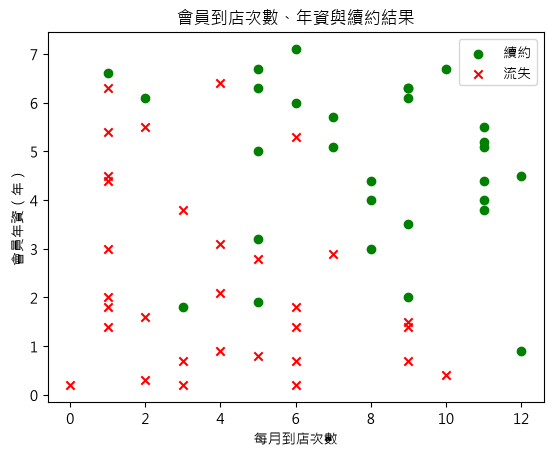

In [3]:
renew = gym[gym["結果"] == "續約"]
churn = gym[gym["結果"] == "流失"]

plt.scatter(renew["到店次數"], renew["會員年資"], color="green", label="續約")
plt.scatter(churn["到店次數"], churn["會員年資"], color="red", marker="x", label="流失")
plt.title("會員到店次數、年資與續約結果")
plt.xlabel("每月到店次數")
plt.ylabel("會員年資（年）")
plt.legend()
plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `gym[gym["結果"] == "續約"]` | 篩選出結果是續約的會員（第 5 堂的篩選，`==` 是「等於」） |
| 兩次 `plt.scatter` | 兩類分別畫，用不同顏色和形狀 |

#### 觀察
- **右上角**（常來、年資久）幾乎都是綠點 → 續約。
- **左下角**（少來、年資短）幾乎都是紅叉 → 流失。
- **中間交界處**兩種混在一起 → 這些是最難判斷的會員，模型最容易在這裡犯錯。

### 步驟 3：準備 X、y，切分資料

In [4]:
X = gym[["到店次數", "會員年資"]]
y = gym["結果"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("訓練集：", X_train.shape, "測試集：", X_test.shape)
print("測試集裡的類別：")
print(y_test.value_counts())

訓練集： (45, 2) 測試集： (15, 2)
測試集裡的類別：
結果
流失    8
續約    7
Name: count, dtype: int64


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `X = gym[[...]]`、`y = gym[...]` | 第 8 堂：X 兩層中括號、y 一層 |
| `test_size=0.25` | 60 × 0.25 = 15 位當測試集 |
| `stratify=y` | **新參數：分層抽樣**。讓訓練集和測試集裡「續約／流失」的比例，都和原始資料差不多 |

#### 為什麼分類問題要加 `stratify=y`？
如果運氣不好，隨機切出來的測試集可能 13 個流失、2 個續約，考題就偏了。
加上 `stratify=y`，測試集就會是 7 個續約、8 個流失，和原本「一半一半」的比例一致。
**分類問題建議都加上 `stratify=y`**；迴歸問題（預測數字）不用。

### 步驟 4：KNN 模型

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

result = pd.DataFrame({
    "到店次數": X_test["到店次數"],
    "會員年資": X_test["會員年資"],
    "實際": y_test,
    "預測": y_pred
})
result["對錯"] = np.where(result["實際"] == result["預測"], "○", "✕")
print(result)

    到店次數  會員年資  實際  預測 對錯
54     4   2.1  流失  流失  ○
23     9   3.5  續約  續約  ○
51    11   4.0  續約  續約  ○
18     6   1.8  流失  流失  ○
35     7   5.7  續約  續約  ○
29     5   1.9  續約  流失  ✕
39     1   4.5  流失  流失  ○
40     5   0.8  流失  流失  ○
32     5   2.8  流失  流失  ○
58     8   4.0  續約  續約  ○
28     9   6.3  續約  續約  ○
20     5   6.7  續約  續約  ○
11     1   6.3  流失  流失  ○
57     2   0.3  流失  流失  ○
12     1   3.0  流失  流失  ○


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `KNeighborsClassifier(n_neighbors=5)` | 建立 KNN，K = 5（問 5 個鄰居） |
| `knn.fit(X_train, y_train)` | 第 8 堂：只用訓練集。對 KNN 來說就是「把這 45 位會員記下來」 |
| `knn.predict(X_test)` | 對 15 位測試會員作答，得到 15 個**類別**（不是數字） |
| `np.where(條件, "○", "✕")` | **新指令**：條件成立填 ○，不成立填 ✕。像 Excel 的 IF |

#### 觀察
15 位裡只有 1 位答錯（✕）。可以看看他的到店次數和年資，是不是剛好在步驟 2 圖上的「交界處」。

#### 分類模型的分數：正確率

In [6]:
# 方法一：自己算
correct = (y_pred == y_test)
print("每一題對不對：", correct.tolist())
print("自己算的正確率：", correct.mean())

# 方法二：score()
print("score() 正確率：", knn.score(X_test, y_test))

每一題對不對： [True, True, True, True, True, False, True, True, True, True, True, True, True, True, True]
自己算的正確率： 0.9333333333333333
score() 正確率： 0.9333333333333333


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `y_pred == y_test` | 一題一題比對，得到 True／False |
| `.mean()` | True 當 1、False 當 0，平均起來就是「答對的比例」（第 6 堂 `isnull().sum()` 也是把 True 當 1） |
| `knn.score(X_test, y_test)` | 分類模型的 score 就是**正確率**：14 ÷ 15 ≈ 0.933 |

> **重要：** 同樣叫 `score()`，迴歸模型給的是 R²，分類模型給的是正確率。
> 兩個都是「越接近 1 越好」，但意思不一樣。

### 步驟 5：預測新會員，看看它問了哪些鄰居

In [7]:
new_members = pd.DataFrame({
    "到店次數": [8, 2, 6],
    "會員年資": [4.0, 1.0, 2.0]
})

new_members["KNN預測"] = knn.predict(new_members[["到店次數", "會員年資"]])
print(new_members)

   到店次數  會員年資 KNN預測
0     8   4.0    續約
1     2   1.0    流失
2     6   2.0    流失


In [8]:
# 第一位新會員（每月 8 次、年資 4 年）的 5 個鄰居是誰？
distances, indices = knn.kneighbors(new_members[["到店次數", "會員年資"]].iloc[[0]])

neighbors = X_train.iloc[indices[0]].copy()
neighbors["結果"] = y_train.iloc[indices[0]].values
neighbors["距離"] = distances[0].round(2)
print(neighbors)

    到店次數  會員年資  結果    距離
30     8   4.4  續約  0.40
7      8   3.0  續約  1.00
56     7   5.1  續約  1.49
34     7   2.9  流失  1.49
50     9   2.0  續約  2.24


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `.iloc[[0]]` | **新指令**：用「位置」取第 0 列（第一位）。兩層中括號讓它保持二維 |
| `knn.kneighbors(...)` | 找出最近的 K 個鄰居，回傳他們的**距離**和在訓練集裡的**位置** |
| `X_train.iloc[indices[0]]` | 用位置把那 5 位鄰居的資料取出來 |
| `.copy()` | 複製一份，避免修改到原本的 X_train |

`iloc`、`kneighbors`、`copy` 這三個只是為了「看到鄰居」才用，不用背。

#### 觀察：多數決
5 個鄰居裡有 **4 位續約、1 位流失** → 4 : 1，多數是續約 → 預測**續約**。
這就是 KNN 判斷的全部過程。

In [9]:
# 也可以直接看投票比例
print("類別順序：", knn.classes_)
print(knn.predict_proba(new_members[["到店次數", "會員年資"]]))

類別順序： ['流失' '續約']
[[0.2 0.8]
 [0.8 0.2]
 [0.8 0.2]]


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `knn.classes_` | 模型認識的類別，以及它們的順序（依照文字排序） |
| `knn.predict_proba(...)` | **predict probability**：每一類的投票比例（機率） |

第一位是 `[0.2, 0.8]`：流失 0.2（1 票）、續約 0.8（4 票）。
`predict_proba` 很實用：店長可以優先關心「續約機率只有 0.4～0.6」這種**搖擺不定**的會員。

### 步驟 6：K 選多少比較好？

In [10]:
for k in [1, 3, 5, 7, 9, 15]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    print("K =", k, "  訓練集：", round(model.score(X_train, y_train), 3),
          "  測試集：", round(model.score(X_test, y_test), 3))

K = 1   訓練集： 1.0   測試集： 0.8
K = 3   訓練集： 0.889   測試集： 0.867
K = 5   訓練集： 0.778   測試集： 0.933
K = 7   訓練集： 0.8   測試集： 0.933
K = 9   訓練集： 0.8   測試集： 0.933
K = 15   訓練集： 0.822   測試集： 0.933


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `for k in [1, 3, 5, 7, 9, 15]:` | **新語法：迴圈**。讓 k 依序等於清單裡的每個數字，每次都執行一遍下面**縮排**的程式 |
| 縮排（前面空 4 格） | 代表「這幾行屬於迴圈裡面」，要重複執行 |

迴圈等於幫你把同一段程式複製 6 次、每次換一個 K，省得手動改 6 次。

#### 觀察
- **K = 1**：訓練集 1.0（滿分），測試集只有 0.8。
  只問一個鄰居時，每位訓練會員最近的鄰居就是「自己」，所以訓練集一定全對，這是**背答案**。碰到新會員就沒那麼準了。
- **K = 5 以上**：測試集穩定在 0.933。
- 選 K 的方法：**看測試集分數**，不看訓練集分數。（第 15 堂會學更嚴謹的方法。）
- 小提醒：K = 5 時訓練集分數（0.778）反而比測試集（0.933）低。資料很少時偶爾會這樣，是正常的，判斷時一樣以測試集為準。

### 步驟 7：決策樹模型

In [11]:
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)

print("決策樹正確率：", round(tree.score(X_test, y_test), 3))

決策樹正確率： 0.933


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `DecisionTreeClassifier(max_depth=2, ...)` | 建立決策樹，**最多問 2 層**問題 |
| `random_state=42` | 決策樹內部也有一點隨機性，固定下來讓結果每次一樣 |

除了建立模型這一行，其他（fit、score）都和 KNN、線性迴歸**一模一樣**。這就是 sklearn 好用的地方：**換模型只要換一行。**

#### 把決策樹畫出來

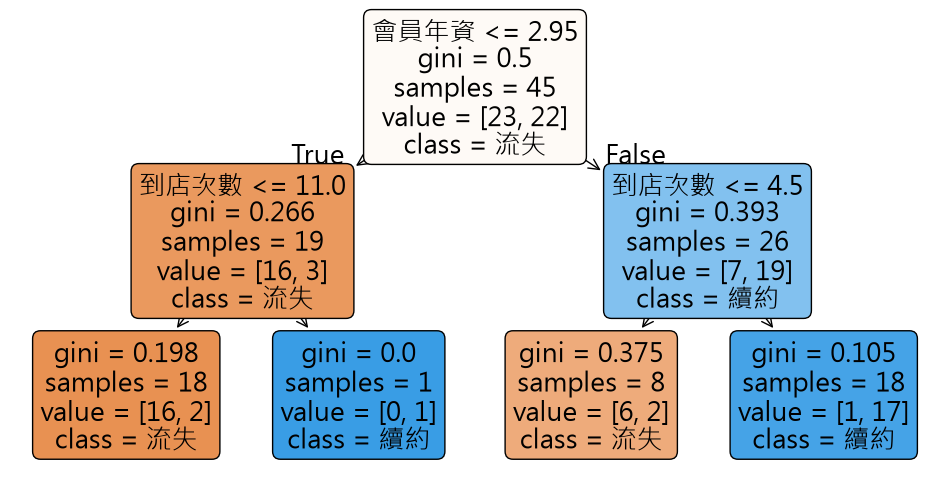

In [12]:
plt.figure(figsize=(12, 6))
plot_tree(tree,
          feature_names=["到店次數", "會員年資"],
          class_names=tree.classes_,
          filled=True,
          rounded=True)
plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `plot_tree(tree, ...)` | 把樹畫出來 |
| `feature_names=` | 告訴它特徵的名字，圖上才會寫「會員年資」而不是 x[1] |
| `class_names=tree.classes_` | 類別名字 |
| `filled=True` | 依照類別塗顏色，顏色越深代表那一格越「純」 |

#### 怎麼看每個方框
| 方框裡的文字 | 意思 |
| :--- | :--- |
| `會員年資 <= 2.95` | 這一層問的是非題（**是（True）→ 往左走，否（False）→ 往右走**） |
| `samples = 45` | 有幾位會員走到這一格 |
| `value = [23, 22]` | 這一格裡流失、續約各幾位（順序同 `classes_`） |
| `class = 流失` | 如果停在這一格，判斷為哪一類（多數決） |
| `gini` | 「混亂程度」，0 代表全部同一類，越大越混。樹會挑讓 gini 降最多的問題來問 |

In [13]:
# 也可以印成文字規則
print(export_text(tree, feature_names=["到店次數", "會員年資"]))

|--- 會員年資 <= 2.95
|   |--- 到店次數 <= 11.00
|   |   |--- class: 流失
|   |--- 到店次數 >  11.00
|   |   |--- class: 續約
|--- 會員年資 >  2.95
|   |--- 到店次數 <= 4.50
|   |   |--- class: 流失
|   |--- 到店次數 >  4.50
|   |   |--- class: 續約



#### 用白話讀出規則

```
會員年資 ≤ 2.95 年？
├─ 是（年資短）→ 到店次數 ≤ 11 次？
│                ├─ 是 → 流失
│                └─ 否 → 續約（年資短，但每月來 12 次以上）
└─ 否（年資長）→ 到店次數 ≤ 4.5 次？
                 ├─ 是 → 流失（老會員但很少來）
                 └─ 否 → 續約
```

**給店長的白話報告：**
> 「新會員（未滿 3 年）除非每月來超過 11 次，否則容易流失；老會員只要每月來超過 4 次，大多會續約。
> **建議優先關心：年資 3 年以上、但每月來不到 5 次的會員。**」

**但要注意：** 「年資短但每月來超過 11 次 → 續約」這片葉子，圖上寫 `samples = 1`，也就是**只有 1 位會員**支持這條規則。證據太少，向主管報告時要說明這條不太可靠。
讀決策樹時，記得同時看 `samples`：人數越多的葉子，規則越可信。

這就是決策樹的**可解釋性**：模型的判斷規則可以直接變成管理建議。KNN 就做不到這一點，它只能說「因為你的鄰居都這樣」。

### 步驟 8：把決策樹的規則畫在散佈圖上

決策樹每問一個問題，就是在圖上畫一條**直線**，把空間切成一塊一塊的長方形。

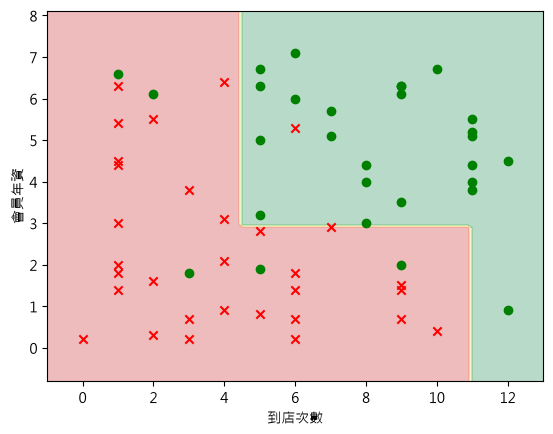

In [45]:
from sklearn.inspection import DecisionBoundaryDisplay

# 自動畫出決策樹切出來的長方形色塊
DecisionBoundaryDisplay.from_estimator(
    tree, X_train, response_method="predict", alpha=0.3, cmap="RdYlGn"
)

# 再把原本的散佈圖疊上去即可
plt.scatter(renew["到店次數"], renew["會員年資"], color="green", label="續約")
plt.scatter(churn["到店次數"], churn["會員年資"], color="red", marker="x", label="流失")
plt.show()

NameError: name 'df' is not defined

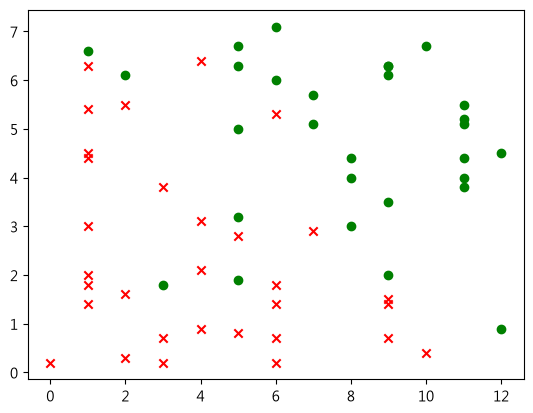

In [ ]:
plt.scatter(renew["到店次數"], renew["會員年資"], color="green", label="續約")
plt.scatter(churn["到店次數"], churn["會員年資"], color="red", marker="x", label="流失")

# 第一個問題：年資 2.95（橫線）
plt.plot([0, 12], [2.95, 2.95], color="black", linestyle="--")
# 年資短的那一塊，再問到店次數 11（直線）
plt.plot([11, 11], [0, 2.95], color="blue", linestyle="--")
# 年資長的那一塊，再問到店次數 4.5（直線）
plt.plot([4.5, 4.5], [2.95, 7.5], color="blue", linestyle="--")

plt.title("決策樹把空間切成長方形")
plt.xlabel("每月到店次數")
plt.ylabel("會員年資（年）")
plt.legend()
plt.show()

#### 觀察
三條虛線把圖切成四塊：
- **右上塊**（年資 > 2.95 且到店 > 4.5）→ 續約區
- **左上塊**（年資 > 2.95 且到店 ≤ 4.5）→ 流失區
- **左下大塊**（年資 ≤ 2.95 且到店 ≤ 11）→ 流失區
- **右下小塊**（年資 ≤ 2.95 且到店 > 11）→ 續約區

KNN 沒有這種清楚的線，它的界線是依照鄰居彎來彎去的。

### 步驟 9：樹太深會怎樣？

In [15]:
for depth in [1, 2, 3, 4, 5]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=42)
    t.fit(X_train, y_train)
    print("深度", depth, "  訓練集：", round(t.score(X_train, y_train), 3),
          "  測試集：", round(t.score(X_test, y_test), 3))

深度 1   訓練集： 0.778   測試集： 0.733
深度 2   訓練集： 0.889   測試集： 0.933
深度 3   訓練集： 0.911   測試集： 0.867
深度 4   訓練集： 0.956   測試集： 0.733
深度 5   訓練集： 1.0   測試集： 0.8


#### 觀察

| 深度 | 訓練集 | 測試集 | 狀況 |
| :--- | :--- | :--- | :--- |
| 1 | 低 | 低 | 只問一題，太簡單，**學不夠** |
| 2 | 中 | **最高** | 剛剛好 |
| 5 | **1.0 滿分** | 下降 | 問太細，把訓練資料**背起來了** |

深度 5 的樹把 45 位訓練會員**全部答對**，但遇到新會員反而變差。
這和第 8 堂「考練習題 100 分、考新題目不及格」是同一件事。

| 現象 | 名稱 | 第幾堂會深入 |
| :--- | :--- | :--- |
| 太簡單、學不夠（深度 1、K 太大） | 欠擬合 Underfitting | 第 12 堂 |
| 太複雜、背答案（深度 5、K = 1） | 過度擬合 Overfitting | 第 12 堂 |

**這就是為什麼一定要看測試集分數。** 只看訓練集，你會以為深度 5 的樹最好。

### 步驟 10：KNN 和決策樹比一比

In [16]:
compare = new_members[["到店次數", "會員年資"]].copy()
compare["KNN"] = knn.predict(compare[["到店次數", "會員年資"]])
compare["決策樹"] = tree.predict(compare[["到店次數", "會員年資"]])
print(compare)

   到店次數  會員年資 KNN 決策樹
0     8   4.0  續約  續約
1     2   1.0  流失  流失
2     6   2.0  流失  流失


| 比較 | KNN | 決策樹 |
| :--- | :--- | :--- |
| 判斷方式 | 找最近 K 個鄰居多數決 | 一連串是非題 |
| 要調的參數 | `n_neighbors`（K） | `max_depth`（深度） |
| 可以解釋嗎 | 普通：只能說「鄰居都這樣」 | **很好**：可以畫成流程圖 |
| `fit()` 在做什麼 | 只是把資料記下來 | 找出最好的問題和門檻 |
| 資料很多時 | 預測變慢（要算所有距離） | 預測很快 |
| 太複雜的時候 | K = 1 會背答案 | 樹太深會背答案 |

兩個模型在這份資料上表現差不多（都是 0.933），實務上通常都試試看，再用**測試集分數**決定用哪一個。

---
## 四、本堂重點整理

### 程式碼
| 程式碼 | 意思 |
| :--- | :--- |
| `KNeighborsClassifier(n_neighbors=5)` | KNN，問 5 個鄰居 |
| `DecisionTreeClassifier(max_depth=2, random_state=42)` | 決策樹，最多問 2 層 |
| `train_test_split(..., stratify=y)` | 分類問題要加，讓兩邊的類別比例一致 |
| `model.score(X_test, y_test)` | 分類模型 → **正確率** |
| `model.predict_proba(X)` | 每一類的機率（KNN 就是投票比例） |
| `model.classes_` | 類別的順序 |
| `plot_tree(...)`、`export_text(...)` | 把決策樹畫成圖、印成文字 |
| `df["欄"].value_counts()` | 每個類別各幾個 |
| `np.where(條件, A, B)` | 條件成立填 A，否則填 B |
| `for k in [...]:` | 迴圈：依序代入每個值，重複執行縮排的程式 |

### 觀念
1. 分類和迴歸的流程一樣，**換模型只要換一行**。
2. 分類模型的 `score()` 是**正確率**，不是 R²。
3. KNN = 物以類聚；決策樹 = 一連串是非題。
4. 決策樹的規則可以直接變成管理建議（**可解釋性**）。
5. K 太小、樹太深都會**背答案**：訓練集分數很高，測試集反而下降。

### 常見錯誤
| 狀況 | 原因 | 解法 |
| :--- | :--- | :--- |
| `IndentationError` | 迴圈裡面的程式沒有縮排 | 迴圈下面的行前面要空 4 格 |
| 測試集類別很不平均 | 沒加 `stratify=y` | 分類問題加上 `stratify=y` |
| 決策樹圖上寫 x[0]、x[1] | 沒給 `feature_names` | 加上 `feature_names=[...]` |
| predict_proba 看不懂哪個是哪類 | 沒看順序 | 印出 `model.classes_` 對照 |

---
## 五、實際練習

### 練習一：改變 K
把 KNN 的 K 改成 3，重新訓練並印出測試集正確率。再用 K = 3 預測那三位新會員，結果有沒有改變？

In [28]:
# 練習一：在這裡寫你的程式
knn3 = KNeighborsClassifier(n_neighbors=3)
knn3.fit(X_train, y_train)
print("K=3 正確率:", round(knn3.score(X_test, y_test), 3))
print(knn3.predict(new_members[["到店次數", "會員年資"]]))

K=3 正確率: 0.867
['續約' '流失' '流失']


In [18]:
# 練習一 參考解答
knn3 = KNeighborsClassifier(n_neighbors=3)
knn3.fit(X_train, y_train)
print("K=3 正確率：", round(knn3.score(X_test, y_test), 3))
print(knn3.predict(new_members[["到店次數", "會員年資"]]))

K=3 正確率： 0.867
['續約' '流失' '流失']


### 練習二：深度 3 的決策樹
訓練一棵 `max_depth=3` 的決策樹，用 `export_text` 印出規則，並回答：
1. 它比深度 2 多問了哪些問題？
2. 測試集正確率比深度 2 高還是低？

In [29]:
# 練習二：在這裡寫你的程式
tree3 = DecisionTreeClassifier(max_depth=3, random_state=41)
tree3.fit(X_train, y_train)
print(export_text(tree3, feature_names=["到店次數", "會員年資"]))
print("深度 3 正確率:", round(tree3.score(X_test, y_test), 3))


|--- 會員年資 <= 2.95
|   |--- 到店次數 <= 11.00
|   |   |--- 會員年資 <= 1.70
|   |   |   |--- class: 流失
|   |   |--- 會員年資 >  1.70
|   |   |   |--- class: 流失
|   |--- 到店次數 >  11.00
|   |   |--- class: 續約
|--- 會員年資 >  2.95
|   |--- 到店次數 <= 4.50
|   |   |--- 會員年資 <= 5.80
|   |   |   |--- class: 流失
|   |   |--- 會員年資 >  5.80
|   |   |   |--- class: 續約
|   |--- 到店次數 >  4.50
|   |   |--- 到店次數 <= 6.50
|   |   |   |--- class: 續約
|   |   |--- 到店次數 >  6.50
|   |   |   |--- class: 續約

深度 3 正確率: 0.867


In [20]:
# 練習二 參考解答
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree3.fit(X_train, y_train)
print(export_text(tree3, feature_names=["到店次數", "會員年資"]))
print("深度 3 正確率：", round(tree3.score(X_test, y_test), 3))
# 深度 3 會在某些葉子再多切一刀，訓練集分數變高，但測試集分數反而比深度 2 低一點 → 開始有背答案的跡象。

|--- 會員年資 <= 2.95
|   |--- 到店次數 <= 11.00
|   |   |--- 會員年資 <= 1.70
|   |   |   |--- class: 流失
|   |   |--- 會員年資 >  1.70
|   |   |   |--- class: 流失
|   |--- 到店次數 >  11.00
|   |   |--- class: 續約
|--- 會員年資 >  2.95
|   |--- 到店次數 <= 4.50
|   |   |--- 會員年資 <= 5.80
|   |   |   |--- class: 流失
|   |   |--- 會員年資 >  5.80
|   |   |   |--- class: 續約
|   |--- 到店次數 >  4.50
|   |   |--- 到店次數 <= 6.50
|   |   |   |--- class: 續約
|   |   |--- 到店次數 >  6.50
|   |   |   |--- class: 續約

深度 3 正確率： 0.867


### 練習三：找出搖擺不定的會員
用 `knn.predict_proba(X_test)` 找出測試集中，**續約機率剛好是 0.4 或 0.6** 的會員（也就是 5 票裡 2:3 或 3:2 的人）。
提示：續約是 `classes_` 裡的第幾個？可以把結果存成 DataFrame 的一欄，再用第 5 堂的篩選。

In [32]:
# 練習三：在這裡寫你的程式
proba = knn.predict_proba(X_test)
check = X_test.copy()
check["實際"] = y_test
check["續約機率"] = proba[:, 1]
print(check[(check["續約機率"] == 0.4) | (check["續約機率"] == 0.6)])

    到店次數  會員年資  實際  續約機率
54     4   2.1  流失   0.4
39     1   4.5  流失   0.4
11     1   6.3  流失   0.4


In [22]:
# 練習三 參考解答
proba = knn.predict_proba(X_test)
check = X_test.copy()
check["實際"] = y_test
check["續約機率"] = proba[:, 1]      # classes_ 是 ['流失', '續約']，續約是第 1 個（從 0 開始數）
print(check[(check["續約機率"] == 0.4) | (check["續約機率"] == 0.6)])
# proba[:, 1] 的意思是「每一列都取第 1 欄」。這些人就是店長最該主動關心的對象。

    到店次數  會員年資  實際  續約機率
54     4   2.1  流失   0.4
39     1   4.5  流失   0.4
11     1   6.3  流失   0.4


### 練習四（挑戰題）：水果分類
下面是 20 顆水果的「重量（克）」和「直徑（公分）」，要分辨是**柳丁**還是**葡萄柚**。
請完成完整流程：畫散佈圖（兩類不同顏色）→ 準備 X、y → 切分（test_size=0.25、random_state=0、stratify=y）→ 用 KNN 和決策樹（max_depth=2）各訓練一次 → 比較正確率 → 印出決策樹規則。

In [37]:
# 練習四：資料（先執行這格）
fruit = pd.DataFrame({
    "重量": [150, 160, 145, 170, 155, 165, 140, 175, 158, 162,
            320, 350, 300, 380, 340, 310, 360, 330, 295, 370],
    "直徑": [7.0, 7.4, 6.8, 7.8, 7.1, 7.5, 6.6, 8.0, 7.2, 7.3,
            10.5, 11.2, 9.8, 12.0, 11.0, 10.1, 11.5, 10.8, 9.6, 11.8],
    "種類": ["柳丁"] * 10 + ["葡萄柚"] * 10
})
print(fruit["種類"].value_counts())

種類
柳丁     10
葡萄柚    10
Name: count, dtype: int64


KNN 正確率: 1.0
tree 正確率: 1.0
|--- 重量 <= 235.00
|   |--- class: 柳丁
|--- 重量 >  235.00
|   |--- class: 葡萄柚



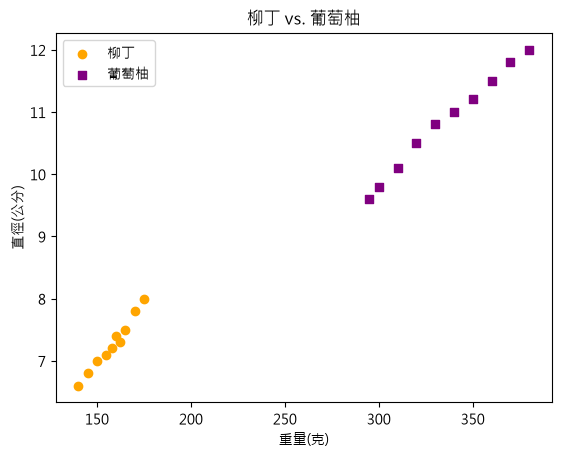

In [ ]:
# 練習四：在這裡寫你的程式
orange = fruit[fruit["種類"] == "柳丁"]
grape = fruit[fruit["種類"] == "葡萄柚"]
plt.scatter(orange["重量"], orange["直徑"], color = "orange", label = "柳丁")
plt.scatter(grape["重量"], grape["直徑"], color = "purple", label = "葡萄柚", marker="s")
plt.title("柳丁 vs. 葡萄柚")
plt.legend()
plt.xlabel("重量(克)")
plt.ylabel("直徑(公分)")
plt.show

Xf = fruit[["重量", "直徑"]]
yf = fruit["種類"]
Xf_train, Xf_test, yf_train, yf_test = train_test_split(Xf, yf, test_size= 0.25, random_state = 0, stratify = yf)

fk = KNeighborsClassifier(n_neighbors=3)
fk.fit(Xf_train, yf_train)
ft = DecisionTreeClassifier(max_depth=2)
ft.fit(Xf_train, yf_train)

print("KNN 正確率:", round(fk.score(Xf_test, yf_test), 3))
print("tree 正確率:", round(ft.score(Xf_test, yf_test), 3))
print(export_text(ft, feature_names=["重量", "直徑"]))


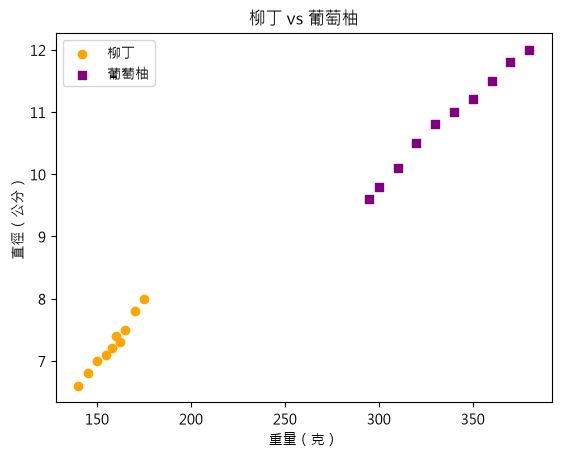

KNN 正確率： 1.0
決策樹正確率： 1.0
|--- 重量 <= 235.00
|   |--- class: 柳丁
|--- 重量 >  235.00
|   |--- class: 葡萄柚



In [25]:
# 練習四 參考解答
orange = fruit[fruit["種類"] == "柳丁"]
grape = fruit[fruit["種類"] == "葡萄柚"]
plt.scatter(orange["重量"], orange["直徑"], color="orange", label="柳丁")
plt.scatter(grape["重量"], grape["直徑"], color="purple", marker="s", label="葡萄柚")
plt.title("柳丁 vs 葡萄柚")
plt.xlabel("重量（克）")
plt.ylabel("直徑（公分）")
plt.legend()
plt.show()

Xf = fruit[["重量", "直徑"]]
yf = fruit["種類"]
Xf_train, Xf_test, yf_train, yf_test = train_test_split(Xf, yf, test_size=0.25, random_state=0, stratify=yf)

fk = KNeighborsClassifier(n_neighbors=3)
fk.fit(Xf_train, yf_train)
ft = DecisionTreeClassifier(max_depth=2, random_state=42)
ft.fit(Xf_train, yf_train)

print("KNN 正確率：", fk.score(Xf_test, yf_test))
print("決策樹正確率：", ft.score(Xf_test, yf_test))
print(export_text(ft, feature_names=["重量", "直徑"]))
# 兩類分得很開，所以兩個模型都是滿分。決策樹只要問一題「重量 ≤ 某個數」就能分開。

---
## 六、小考驗收

先不看筆記回答下面的問題，能回答出來再回到對話中做第 10 堂小考。

1. 分類和迴歸的差別是什麼？各舉一個例子。
2. KNN 怎麼判斷一位新會員會不會續約？
3. K = 1 時，訓練集正確率為什麼一定是 1.0？
4. 分類問題的 `train_test_split` 建議加上什麼參數？為什麼？
5. 分類模型的 `score()` 代表什麼？和線性迴歸的 `score()` 一樣嗎？
6. 決策樹圖上「是」往哪邊走？
7. 決策樹最大的優點是什麼？
8. 深度 5 的樹訓練集 1.0、測試集 0.8，深度 2 的樹訓練集 0.89、測試集 0.93，應該選哪一棵？為什麼？

<details>
<summary>點我看參考答案</summary>

1. 分類預測類別（續約／流失），迴歸預測數字（房價）。
2. 找出和他最近的 K 位舊會員，看哪一類比較多（多數決）。
3. 每位訓練會員最近的鄰居就是他自己，所以一定答對（背答案）。
4. `stratify=y`，讓訓練集和測試集的類別比例和原本一樣，考題才公平。
5. 正確率（答對的比例）。不一樣，線性迴歸的是 R²，但兩者都是越接近 1 越好。
6. 往左。
7. 可以解釋，規則能直接畫成流程圖、變成管理建議。
8. 深度 2。要看測試集分數；深度 5 是在背答案（過度擬合）。

</details>

### 下一堂預告：第 11 堂 模型評估
今天用「正確率」評估分類模型。但想像一下：如果 100 位會員裡有 95 位續約，一個**什麼都不學、永遠猜「續約」**的模型，正確率也有 95%！
第 11 堂會學到更好的評估方法：**混淆矩陣、Precision（精確率）、Recall（召回率）**，看出模型到底錯在哪裡。